# Exercise 1.4 | Panel Data (Long Format)

In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# File Path
file_path = 'https://econ-0150.tayweid.io/data/'

## Coffee Shop Transactions

Use `Coffee_Sales_Reciepts.csv` to help inform where to hire a barista.

This is **long format panel data**: each transaction is a row, and a column identifies the shop.

In [2]:
# Load Dataset
sales = pd.read_csv(file_path + 'Coffee_Sales_Reciepts.csv', index_col=0)
sales.head()

,transaction_id,staff_id,customer_id,product_id,quantity,unit_price,Hours,Shop
0,7,12,558,52,1,2.50,12,Shop A
1,11,17,781,27,2,3.50,15,Shop A
2,19,17,788,46,2,2.50,14,Shop A
3,32,12,683,23,2,2.50,16,Shop A
4,33,17,99,34,1,2.45,19,Shop A


### Bar Chart: Which shop is busiest?

<Axes: xlabel='Shop', ylabel='count'>

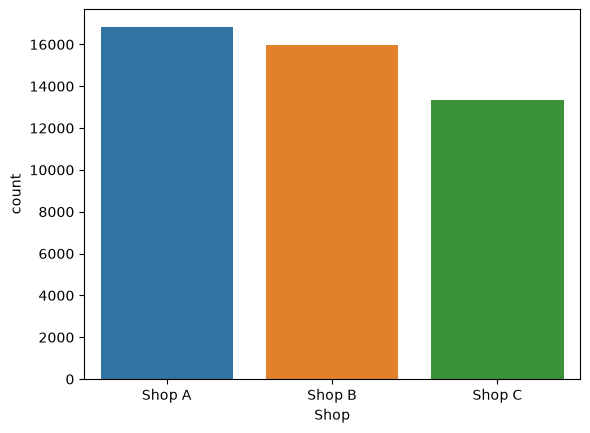

In [3]:
# Bar graph
sns.countplot(sales, x='Shop', hue='Shop')

### Histogram: What time of day is busiest?

<Axes: xlabel='Hours', ylabel='Count'>

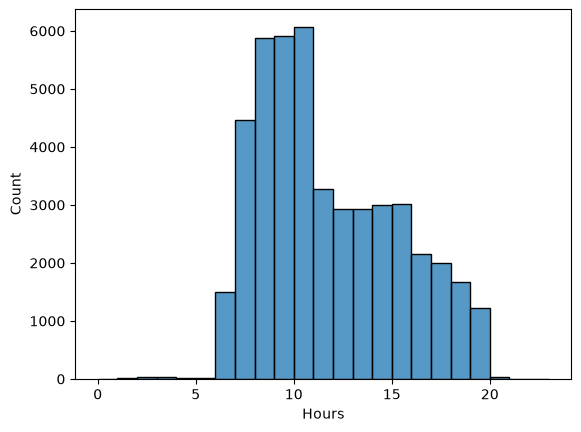

In [4]:
# Histogram
sns.histplot(sales, x='Hours', bins=range(0,24,1))

### Multi-Histogram: Breaking out by shop

<Axes: xlabel='Hours', ylabel='Count'>

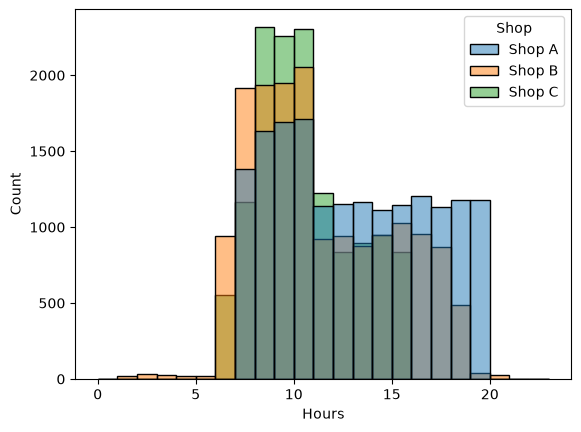

In [5]:
# Multi-histogram
sns.histplot(sales, x='Hours', hue='Shop', bins=range(0,24,1))

### Faceted Histogram: Each shop gets its own panel

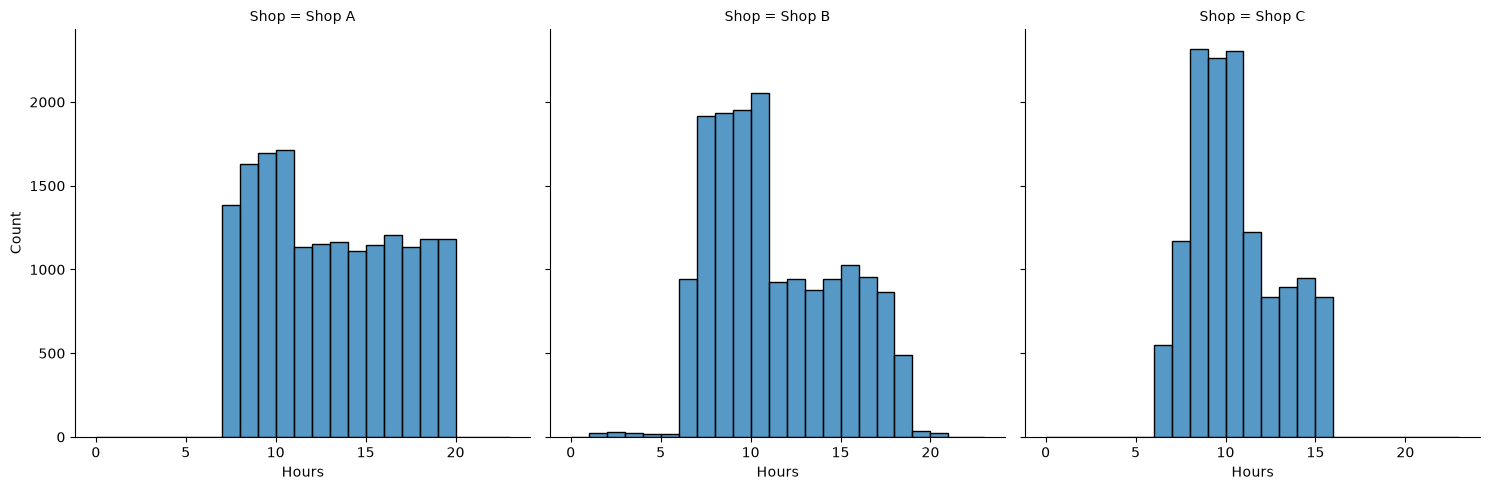

In [6]:
# Faceted histogram
sns.displot(sales, x='Hours', col='Shop', bins=range(0,24,1))

### Multiple Line Graph: The Groupby Approach

First, create a summary table that counts transactions by shop and hour.

In [7]:
# Create a summary table
counts = sales.groupby(['Shop', 'Hours']).size().reset_index(name='Count')
counts.head()

,Shop,Hours,Count
0,Shop A,7,1383
1,Shop A,8,1632
2,Shop A,9,1693
3,Shop A,10,1711
4,Shop A,11,1136


Now plot the summary table using `lineplot`.

<Axes: xlabel='Hours', ylabel='Count'>

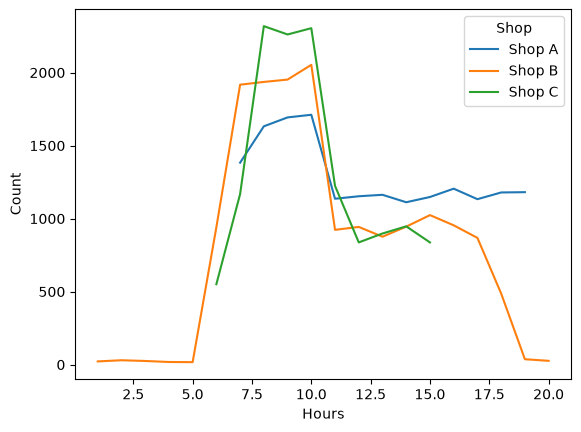

In [8]:
# Multiple-Line Graph using lineplot
sns.lineplot(counts, x='Hours', y='Count', hue='Shop')

### Multiple Line Graph: The Shortcut

If we just want the figure without the summary table, we can let `histplot` do the counting for us using `element='poly'` and `fill=False`.

<Axes: xlabel='Hours', ylabel='Count'>

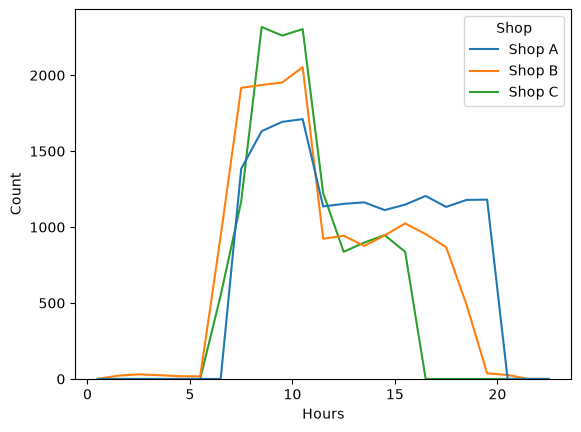

In [9]:
# Multiple-Line Graph using histplot shortcut
sns.histplot(sales, x='Hours', hue='Shop', bins=range(0,24,1), element='poly', fill=False)